# Examen ICCD753 Recuperación de Información

## 1. Objetivo

Desarrollar un sistema de recuperación de información sobre un corpus asignado. El sistema deberá indexar los documentos, recuperar y ordenar resultados mediante TF-IDF con similitud coseno y BM25, y exponer la búsqueda como un servicio web publicado en internet.

Se evaluará el servicio enviando consultas desde un cliente (p.ej. Postman) y contrastando los resultados con los juicios de relevancia (*qrels*) del corpus.

## 2. Corpus asignado

Cada estudiante recibirá un conjunto de datos. Todos contienen documentos, consultas y qrels. Se utilizarán los identificadores originales de los documentos para que los resultados puedan evaluarse.

| Corpus | Documentos y consultas | Qrels |
| --- | --- | --- |
| NFCorpus | [BeIR/nfcorpus](https://huggingface.co/datasets/BeIR/nfcorpus) | [BeIR/nfcorpus-qrels](https://huggingface.co/datasets/BeIR/nfcorpus-qrels) |
| SciFact | [BeIR/scifact](https://huggingface.co/datasets/BeIR/scifact) | [BeIR/scifact-qrels](https://huggingface.co/datasets/BeIR/scifact-qrels) |

## 3. Requisitos del sistema

### 3.1. Preparación e indexación

El sistema deberá:

1. Cargar e indexar los documentos del corpus asignado.
2. Aplicar y documentar las decisiones de preprocesamiento: tokenización, normalización, eliminación de stopwords y stemming o lematización.
3. Construir un vocabulario y un índice invertido que permita recuperar documentos.
4. Conservar la relación entre cada documento indexado y su identificador original.

La unidad de evaluación será el documento original, porque los qrels relacionan consultas con identificadores de documentos. No se debe dividir el texto en fragmentos.

### 3.2. Modelos de recuperación

Para cualquier consulta de texto, el sistema deberá producir dos rankings independientes:

- TF-IDF con similitud coseno.
- BM25.

Cada ranking deberá ordenar los documentos por puntuación de relevancia y permitir solicitar los primeros `k` resultados.

### 3.3. Servicio web

El sistema deberá estar publicado en internet y ofrecer, como mínimo, los siguientes endpoints:

**Comprobación de disponibilidad**

```http
GET /health
```

**Búsqueda**

```http
POST /search
Content-Type: application/json
```

Ejemplo de solicitud:

```json
{
  "query": "texto de la consulta",
  "model": "bm25",
  "top_k": 10
}
```

El campo `model` deberá aceptar `bm25` y `tfidf`. Una respuesta tendrá esta estructura:

```json
{
  "model": "bm25",
  "results": [
    {
      "rank": 1,
      "document_id": "identificador_original",
      "score": 8.42,
      "title": "Título, si está disponible",
      "snippet": "Fragmento del documento recuperado"
    }
  ]
}
```

Los resultados deberán estar ordenados de mayor a menor puntuación, no contener documentos duplicados y respetar el valor solicitado de `top_k`. El servicio debe aceptar consultas que el estudiante no conozca de antemano.

## 4. Evaluación de la recuperación

Cada estudiante debe evaluar ambos modelos con consultas de la partición `test` y sus qrels. Presentará, como mínimo:

- Precision@10.
- Recall@10.
- NDCG@10.
- Una comparación de los resultados de TF-IDF y BM25.

En el Jupyter Notebook se deberá indicar qué consultas se utilizaron y permitir reproducir los cálculos. La evaluación del docente podrá utilizar otras consultas del mismo conjunto.

## 5. Prueba del docente

El docente accederá a la URL entregada y realizará solicitudes desde un cliente de web service para comprobar:

1. La disponibilidad del servicio.
2. El funcionamiento de TF-IDF y BM25.
3. El formato, orden y validez de los resultados.
4. La correspondencia de los `document_id` con el corpus y los qrels.
5. La respuesta ante consultas no incluidas en los ejemplos de entrega.

## 6. Entregables

Cada estudiante entregará:

1. La URL pública del servicio web, accesible durante el período de revisión.
2. El código en Jupyter Notebook con los resultados de la ejecución de cada bloque de código, incluyendo los resultados de las métricas de evaluación de los modelos de recuperación.

Se evaluará que ambos modelos funcionen correctamente y que cada estudiante interprete sus resultados.

## Introducción

*(Borrador.)* Este notebook desarrolla un sistema de recuperación de información **léxico** sobre el corpus **SciFact** (BEIR):
- 5183 resúmenes científicos;
- 300 consultas de test, que son afirmaciones científicas, con sus juicios de relevancia.

Se implementan desde cero, sin librerías de IR, un índice invertido y dos modelos de ranking, **TF-IDF con similitud coseno** y **BM25**. Se evalúan con P@10, R@10 y NDCG@10 y se exponen como servicio web JSON (FastAPI), publicado en Hugging Face Spaces.

Todo el código del servicio está en un único fichero, `app.py`, que se **genera desde este notebook** con `%%writefile` (fases 2, 3 y 5). Así el código evaluado aquí es exactamente el que se despliega.

| Sección | Contenido |
|---|---|
| 1. Carga y exploración del corpus | Descarga de BeIR/scifact y qrels de test, estadísticas, `corpus.jsonl` |
| 2. Preprocesamiento e índice invertido | Decisiones de preprocesamiento, `InvertedIndex` y verificación |
| 3. Modelos de recuperación | Fórmulas e implementación de TF-IDF y BM25, pruebas de corrección |
| 4. Evaluación | P@10, R@10 y NDCG@10 en las 300 consultas de test, comparación, interpretación |
| 5. Servicio web | API FastAPI (`/health`, `/search`) y pruebas locales |
| 6. Pruebas del servicio desplegado | Llamadas a la URL pública |
| Conclusiones | Resumen de resultados y limitaciones |

## 1. Carga y exploración del corpus

En esta fase se cargan los tres componentes del corpus **SciFact** (BEIR):

- **Documentos** (`BeIR/scifact`, configuración `corpus`): resúmenes científicos con `_id`, `title` y `text`.
- **Consultas** (`BeIR/scifact`, configuración `queries`): afirmaciones científicas (*claims*).
- **Juicios de relevancia** (`BeIR/scifact-qrels`, partición `test`): pares `(query-id, corpus-id, score)`.

**Decisiones:**

1. Se usa `datasets.load_dataset`, que se verificó que funciona con estos repositorios (publicados en formato parquet, sin script de carga). Como respaldo, si fallara (p. ej. por la retirada de los scripts de carga en `datasets>=4`), se descargan directamente los ficheros parquet de la rama `refs/convert/parquet` con `huggingface_hub`.
2. Todos los identificadores se tratan como **`str`**. En los qrels vienen como `int64`, mientras que en el corpus son cadenas; si no se unifican, la evaluación no encontraría coincidencias.
3. La unidad de recuperación es el **documento completo** (título + resumen), sin dividirlo en fragmentos, porque los qrels relacionan consultas con identificadores de documento.

In [1]:
# Imports de la fase 1
import json
import pandas as pd
import matplotlib.pyplot as plt

def cargar_scifact():
    """Devuelve (corpus, queries, qrels_test) como DataFrames de pandas.

    Primero intenta con `datasets.load_dataset`; si falla, descarga los parquet
    de la rama refs/convert/parquet con huggingface_hub.
    """
    try:
        from datasets import load_dataset
        corpus  = load_dataset("BeIR/scifact", "corpus")["corpus"].to_pandas()
        queries = load_dataset("BeIR/scifact", "queries")["queries"].to_pandas()
        qrels   = load_dataset("BeIR/scifact-qrels")["test"].to_pandas()
        metodo = "datasets.load_dataset"
    except Exception as e:
        print("load_dataset falló:", type(e).__name__, e)
        from huggingface_hub import hf_hub_download
        def parquet(repo, fichero):
            ruta = hf_hub_download(repo, fichero, repo_type="dataset",
                                   revision="refs/convert/parquet")
            return pd.read_parquet(ruta)
        corpus  = parquet("BeIR/scifact", "corpus/corpus/0000.parquet")
        queries = parquet("BeIR/scifact", "queries/queries/0000.parquet")
        qrels   = parquet("BeIR/scifact-qrels", "default/test/0000.parquet")
        metodo = "huggingface_hub (parquet)"
    print("Método de carga utilizado:", metodo)
    return corpus, queries, qrels

corpus_df, queries_df, qrels_test = cargar_scifact()

# Unificar identificadores como str (en los qrels vienen como int64)
corpus_df["_id"]  = corpus_df["_id"].astype(str)
queries_df["_id"] = queries_df["_id"].astype(str)
qrels_test["query-id"]  = qrels_test["query-id"].astype(str)
qrels_test["corpus-id"] = qrels_test["corpus-id"].astype(str)

# Valores nulos -> cadena vacía para trabajar siempre con texto
corpus_df[["title", "text"]] = corpus_df[["title", "text"]].fillna("")

print("Columnas corpus :", list(corpus_df.columns))
print("Columnas queries:", list(queries_df.columns))
print("Columnas qrels  :", list(qrels_test.columns))
corpus_df.head(3)

Método de carga utilizado: datasets.load_dataset
Columnas corpus : ['_id', 'title', 'text']
Columnas queries: ['_id', 'title', 'text']
Columnas qrels  : ['query-id', 'corpus-id', 'score']


,_id,title,text
0,4983,Microstructural development of human newborn c...,Alterations of the architecture of cerebral wh...
1,5836,Induction of myelodysplasia by myeloid-derived...,Myelodysplastic syndromes (MDS) are age-depend...
2,7912,"BC1 RNA, the transcript from a master gene for...",ID elements are short interspersed elements (S...


### 1.1. Estadísticas generales

Se cuentan documentos, consultas (totales y de test) y pares de qrels, y se comprueba la integridad: identificadores únicos, de tipo `str`, y que todos los documentos y consultas citados en los qrels existan en el corpus y en el fichero de consultas. Las **consultas de test** son las que aparecen en los qrels de la partición `test`.

In [2]:
# Conjunto de consultas de test = las que tienen juicios en qrels/test
test_qids = set(qrels_test["query-id"])

print(f"Documentos en el corpus        : {len(corpus_df)}")
print(f"Consultas totales              : {len(queries_df)}")
print(f"Consultas de test (con qrels)  : {len(test_qids)}")
print(f"Pares (query, doc) en qrels    : {len(qrels_test)}")
print(f"Valores de score en qrels      : {sorted(qrels_test['score'].unique().tolist())}")

# Integridad de identificadores
print()
print("¿_id de documentos únicos?           ", corpus_df["_id"].is_unique)
print("¿_id de documentos son str?          ", corpus_df["_id"].map(type).eq(str).all())
print("¿corpus-id de qrels son str?         ", qrels_test["corpus-id"].map(type).eq(str).all())
print("¿Todos los corpus-id están en corpus?", set(qrels_test["corpus-id"]) <= set(corpus_df["_id"]))
print("¿Todas las query-id test en queries? ", test_qids <= set(queries_df["_id"]))
print("Ejemplos de _id:", corpus_df["_id"].head(5).tolist())

Documentos en el corpus        : 5183
Consultas totales              : 1109
Consultas de test (con qrels)  : 300
Pares (query, doc) en qrels    : 339
Valores de score en qrels      : [1]

¿_id de documentos únicos?            True
¿_id de documentos son str?           True
¿corpus-id de qrels son str?          True
¿Todos los corpus-id están en corpus? True
¿Todas las query-id test en queries?  True
Ejemplos de _id: ['4983', '5836', '7912', '18670', '19238']


### 1.2. Documentos relevantes por consulta

Distribución del número de documentos relevantes por consulta de test. Si la mayoría de consultas tiene muy pocos relevantes, Precision@10 queda acotada superiormente (con 1 relevante, P@10 ≤ 0,1), por lo que Recall@10 y NDCG@10 serán más informativas.

In [3]:
rel_por_query = qrels_test.groupby("query-id").size()
print(rel_por_query.describe().round(2))
print()
print("Nº de consultas según cuántos relevantes tienen:")
print(rel_por_query.value_counts().sort_index().rename_axis("relevantes").rename("consultas"))

count    300.00
mean       1.13
std        0.53
min        1.00
25%        1.00
50%        1.00
75%        1.00
max        5.00
dtype: float64

Nº de consultas según cuántos relevantes tienen:
relevantes
1    277
2     14
3      4
4      3
5      2
Name: consultas, dtype: int64


### 1.3. Longitud de los documentos y títulos vacíos

La longitud se mide en palabras separadas por espacios (todavía sin preprocesar) sobre `title + text`, que es el texto que se indexará. Interesa porque BM25 normaliza por la longitud del documento respecto a la media (`avgdl`).

count    5183.0
mean      214.6
std        87.3
min        33.0
25%       158.0
50%       204.0
75%       260.0
max      1541.0
dtype: float64

Documentos sin título: 0
Documentos sin texto : 0


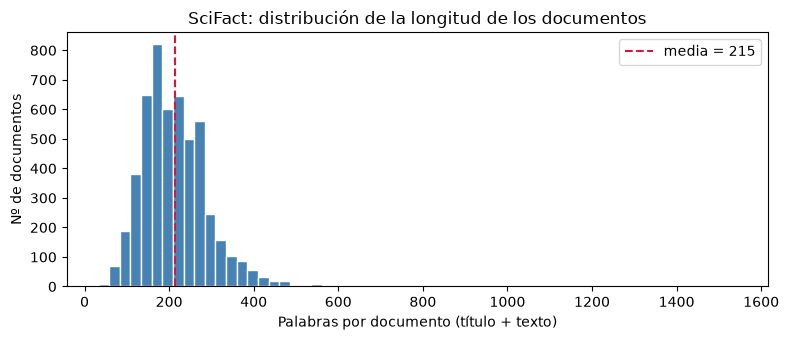

In [4]:
# Longitud en palabras (split por espacios) del texto que se indexará
long_docs = (corpus_df["title"] + " " + corpus_df["text"]).str.split().str.len()
print(long_docs.describe().round(1))

sin_titulo = (corpus_df["title"].str.strip() == "").sum()
sin_texto  = (corpus_df["text"].str.strip() == "").sum()
print(f"\nDocumentos sin título: {sin_titulo}")
print(f"Documentos sin texto : {sin_texto}")

# Histograma de longitudes
plt.figure(figsize=(8, 3.5))
plt.hist(long_docs, bins=60, color="steelblue", edgecolor="white")
plt.axvline(long_docs.mean(), color="crimson", ls="--", label=f"media = {long_docs.mean():.0f}")
plt.xlabel("Palabras por documento (título + texto)")
plt.ylabel("Nº de documentos")
plt.title("SciFact: distribución de la longitud de los documentos")
plt.legend()
plt.tight_layout()
plt.show()

### 1.4. Ejemplos de consultas con sus documentos relevantes

Se muestran dos consultas de test con sus documentos relevantes según los qrels, para ver qué tipo de correspondencia léxica existe entre la afirmación y el resumen.

In [5]:
docs_by_id = corpus_df.set_index("_id")
queries_by_id = queries_df.set_index("_id")

for qid in sorted(test_qids, key=int)[:2]:
    print(f"Query {qid}: {queries_by_id.loc[qid, 'text']}")
    for did in qrels_test.loc[qrels_test["query-id"] == qid, "corpus-id"]:
        d = docs_by_id.loc[did]
        print(f"   -> doc {did} | {d['title']}")
        print(f"      {d['text'][:250]}...")
    print()

Query 1: 0-dimensional biomaterials show inductive properties.
   -> doc 31715818 | New opportunities: the use of nanotechnologies to manipulate and track stem cells.
      Nanotechnologies are emerging platforms that could be useful in measuring, understanding, and manipulating stem cells. Examples include magnetic nanoparticles and quantum dots for stem cell labeling and in vivo tracking; nanoparticles, carbon nanotub...

Query 3: 1,000 genomes project enables mapping of genetic sequence variation consisting of rare variants with larger penetrance effects than common variants.
   -> doc 14717500 | Rare Variants Create Synthetic Genome-Wide Associations
      Genome-wide association studies (GWAS) have now identified at least 2,000 common variants that appear associated with common diseases or related traits (http://www.genome.gov/gwastudies), hundreds of which have been convincingly replicated. It is gen...



### 1.5. Guardar el corpus

Se guarda **solo** `corpus.jsonl` en la raíz del proyecto (una línea JSON por documento con `_id`, `title`, `text`), que es lo que el servicio web cargará al arrancar. Las consultas y qrels de test no se guardan: se vuelven a cargar en el notebook cuando se necesiten para la evaluación.

In [6]:
with open("corpus.jsonl", "w", encoding="utf-8", newline="\n") as f:
    for _id, title, text in corpus_df[["_id", "title", "text"]].itertuples(index=False):
        f.write(json.dumps({"_id": _id, "title": title, "text": text},
                           ensure_ascii=False) + "\n")

# Verificación: releer y comprobar número de líneas e ids
with open("corpus.jsonl", encoding="utf-8") as f:
    lineas = [json.loads(l) for l in f]
print("Documentos guardados:", len(lineas))
print("Primer registro:", {k: v[:60] for k, v in lineas[0].items()})
print("¿ids idénticos al corpus?", [d["_id"] for d in lineas] == corpus_df["_id"].tolist())

Documentos guardados: 5183
Primer registro: {'_id': '4983', 'title': 'Microstructural development of human newborn cerebral white ', 'text': 'Alterations of the architecture of cerebral white matter in '}
¿ids idénticos al corpus? True


## 2. Preprocesamiento e índice invertido

Todo el código del sistema vive en un único fichero, `app.py`, generado desde este notebook con `%%writefile`. En esta fase se escribe su primera parte (imports, `STOPWORDS`, `preprocess` e `InvertedIndex`); las fases siguientes le **añaden** código con `%%writefile -a`.

### Decisiones de preprocesamiento

El mismo `preprocess` se aplica a documentos y consultas, para que ambos se representen en el mismo espacio de términos.

| Paso | Decisión | Justificación |
|---|---|---|
| 1. Minúsculas | `text.lower()` | "Cancer" y "cancer" deben ser el mismo término. |
| 2. Letras griegas | `α→alpha`, `β→beta`, `κ→kappa`, `μ/µ→mu`… | En biomedicina conviven "TNF-α" y "TNF-alpha", "NF-κB" y "NF-kappaB". Sin este mapeo la letra griega se perdería (no es `[a-z0-9]`). |
| 3. Normalización Unicode | NFKD y eliminación de marcas combinantes | Quita acentos y diacríticos ("Café"→"cafe", "naïve"→"naive") y unifica caracteres compatibles. |
| 4. Números | Se eliminan las comas de miles (`1,000`→`1000`); los tokens con dígitos se conservan | En SciFact los números y códigos son muy informativos: genes y proteínas (`p53`, `cd4`, `brca1`), cifras de las afirmaciones ("1,000 genomes"). |
| 5. Tokenización | Regex `[a-z0-9]+(?:-[a-z0-9]+)*` | Alfanumérica; cualquier otro símbolo separa tokens. Los guiones *internos* se capturan para tratarlos aparte. |
| 6. Guiones | Un compuesto genera la **forma unida y sus partes**: `il-6` → `il6`, `il`, `6`; `cell-free` → `cellfree`, `cell`, `free` | Los nombres biomédicos se escriben con y sin guion ("IL-6", "IL6"). La forma unida empareja ambas grafías y las partes permiten emparejar "cell free" o la palabra suelta. El coste es un ligero aumento de la longitud de los documentos con guiones, igual para todos. |
| 7. Stopwords | Lista inglesa de NLTK embebida como literal (sin `nltk.download`) + descarte de tokens de 1 carácter | Palabras funcionales sin poder discriminativo. Los tokens de 1 carácter (`6`, `t` de `t-cell`) son ruido; su información se conserva en la forma unida (`il6`, `tcell`). |
| 8. Stemming | Porter (`nltk.stem.PorterStemmer`), con caché | Agrupa variantes morfológicas ("inhibits", "inhibition", "inhibited"→"inhibit"). Se prefiere stemming a lematización porque no necesita etiquetado POS ni recursos descargables y, para un modelo léxico, mejora la cobertura de la consulta. |

**Texto indexado:** `título + " " + texto` de cada documento completo (sin chunking).

### Estructura del índice invertido

- `vocab`: término → `term_id`; `terms`: lista inversa.
- `postings[term_id] = (doc_idx, tf)`: dos arrays NumPy `int32` alineados y ordenados por `doc_idx`. Los arrays permiten calcular las puntuaciones de forma vectorizada en la fase 3.
- `df[term_id]`, `doc_len[doc_idx]` (en tokens preprocesados), `avgdl` y `N`: todo lo que necesitan TF-IDF y BM25.
- `doc_ids[doc_idx]`: el `_id` **original** (str) de cada documento, que es lo que devuelve el servicio y lo que se compara con los qrels.
- `titles` y `texts`: para devolver el título y el *snippet* en los resultados.

In [7]:
%%writefile app.py
# =============================================================================
# app.py  -  GENERADO desde examen1bim.ipynb (no editar a mano)
# Sistema de recuperación léxico sobre BeIR/scifact: preprocesamiento,
# índice invertido, modelos TF-IDF (coseno) y BM25, y API FastAPI.
# =============================================================================
import json
import re
import unicodedata
from collections import Counter
from functools import lru_cache

import numpy as np
from nltk.stem import PorterStemmer

# -----------------------------------------------------------------------------
# 1) Preprocesamiento
# -----------------------------------------------------------------------------

# Stopwords inglesas (lista de NLTK embebida como literal: no requiere
# nltk.download). Se omiten las formas con apóstrofo ("don't"...), porque el
# tokenizador parte por el apóstrofo y nunca las produce.
STOPWORDS = frozenset("""
i me my myself we our ours ourselves you your yours yourself yourselves he him
his himself she her hers herself it its itself they them their theirs
themselves what which who whom this that these those am is are was were be been
being have has had having do does did doing a an the and but if or because as
until while of at by for with about against between into through during before
after above below to from up down in out on off over under again further then
once here there when where why how all any both each few more most other some
such no nor not only own same so than too very s t can will just don should now
d ll m o re ve y ain aren couldn didn doesn hadn hasn haven isn ma mightn mustn
needn shan shouldn wasn weren won wouldn
""".split())

# Letras griegas frecuentes en biomedicina -> nombre en inglés (TNF-α == TNF-alpha)
GREEK = {
    "α": "alpha", "β": "beta", "γ": "gamma", "δ": "delta",
    "ε": "epsilon", "ζ": "zeta", "η": "eta", "θ": "theta",
    "κ": "kappa", "λ": "lambda", "μ": "mu", "µ": "mu",
    "π": "pi", "σ": "sigma", "τ": "tau", "ω": "omega",
}
_GREEK_RE = re.compile("|".join(GREEK))
_THOUSANDS_RE = re.compile(r"(?<=\d),(?=\d{3}\b)")       # 1,000 -> 1000
_TOKEN_RE = re.compile(r"[a-z0-9]+(?:-[a-z0-9]+)*")        # alfanumérico + guiones internos
MIN_LEN = 2                                                # descarta tokens de 1 carácter

_stemmer = PorterStemmer()


def normalize(text):
    """Minúsculas, griegas -> nombre, y quitar acentos/diacríticos (NFKD)."""
    text = text.lower()
    text = _GREEK_RE.sub(lambda m: GREEK[m.group(0)], text)
    text = unicodedata.normalize("NFKD", text)
    return "".join(ch for ch in text if not unicodedata.combining(ch))


def tokenize(text):
    """Tokeniza texto ya normalizado.

    Un token compuesto con guiones ("il-6", "cell-free") genera la forma unida
    ("il6", "cellfree") y además cada parte ("il", "6", "cell", "free").
    """
    text = _THOUSANDS_RE.sub("", text)
    tokens = []
    for tok in _TOKEN_RE.findall(text):
        if "-" in tok:
            parts = tok.split("-")
            tokens.append("".join(parts))
            tokens.extend(parts)
        else:
            tokens.append(tok)
    return tokens


def remove_stopwords(tokens):
    """Quita stopwords y tokens demasiado cortos."""
    return [t for t in tokens if len(t) >= MIN_LEN and t not in STOPWORDS]


@lru_cache(maxsize=None)
def stem(token):
    """Stemming Porter (cacheado: el vocabulario se repite mucho)."""
    return _stemmer.stem(token)


def preprocess(text):
    """Pipeline completo: normalize -> tokenize -> stopwords -> stem."""
    return [stem(t) for t in remove_stopwords(tokenize(normalize(text or "")))]


# -----------------------------------------------------------------------------
# 2) Índice invertido
# -----------------------------------------------------------------------------

def load_corpus(path="corpus.jsonl"):
    """Lee corpus.jsonl (una línea JSON por documento: _id, title, text)."""
    with open(path, encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]


class InvertedIndex:
    """Índice invertido en memoria.

    Atributos tras build():
      doc_ids  list[str]   _id original del documento en la posición doc_idx
      N        int         nº de documentos
      vocab    dict        término -> term_id
      terms    list[str]   term_id -> término
      df       np.ndarray  df[term_id] = nº de documentos que contienen el término
      postings dict        term_id -> (doc_idx: np.int32[], tf: np.int32[]), doc_idx ascendente
      doc_len  np.ndarray  nº de tokens (preprocesados) de cada documento
      avgdl    float       longitud media de documento
      titles, texts list[str]  para construir títulos y snippets
    """

    def __init__(self):
        self.doc_ids, self.titles, self.texts = [], [], []
        self.vocab, self.terms, self.postings = {}, [], {}
        self.df = np.zeros(0, dtype=np.int32)
        self.doc_len = np.zeros(0, dtype=np.int32)
        self.N, self.avgdl = 0, 0.0

    def build(self, docs):
        """Construye el índice a partir de dicts con _id, title y text."""
        tmp_docs, tmp_tfs = {}, {}            # term_id -> listas temporales
        doc_len = []
        for doc_idx, d in enumerate(docs):
            _id = str(d["_id"])
            title, text = d.get("title") or "", d.get("text") or ""
            self.doc_ids.append(_id)
            self.titles.append(title)
            self.texts.append(text)
            tokens = preprocess(title + " " + text)   # texto indexado = título + texto
            doc_len.append(len(tokens))
            for term, tf in Counter(tokens).items():
                tid = self.vocab.get(term)
                if tid is None:
                    tid = self.vocab[term] = len(self.terms)
                    self.terms.append(term)
                    tmp_docs[tid], tmp_tfs[tid] = [], []
                tmp_docs[tid].append(doc_idx)
                tmp_tfs[tid].append(tf)

        if len(set(self.doc_ids)) != len(self.doc_ids):
            raise ValueError("Hay _id de documento duplicados")

        # Listas -> arrays numpy (doc_idx ya sale ordenado por construcción)
        self.postings = {tid: (np.asarray(tmp_docs[tid], dtype=np.int32),
                               np.asarray(tmp_tfs[tid], dtype=np.int32))
                         for tid in tmp_docs}
        self.df = np.array([len(self.postings[t][0]) for t in range(len(self.terms))],
                           dtype=np.int32)
        self.doc_len = np.asarray(doc_len, dtype=np.int32)
        self.N = len(self.doc_ids)
        self.avgdl = float(self.doc_len.mean()) if self.N else 0.0
        return self

    def get_postings(self, term):
        """Postings de un término YA preprocesado; arrays vacíos si no existe."""
        tid = self.vocab.get(term)
        if tid is None:
            return np.zeros(0, dtype=np.int32), np.zeros(0, dtype=np.int32)
        return self.postings[tid]


Overwriting app.py


### 2.1. Importar `app` y construir el índice

Se importa (y recarga con `importlib.reload`, por si `app.py` cambió en esta misma sesión del kernel) el módulo generado, se lee `corpus.jsonl` y se construye el índice midiendo el tiempo.

In [8]:
import importlib, time
import app
importlib.reload(app)

docs = app.load_corpus("corpus.jsonl")

t0 = time.perf_counter()
index = app.InvertedIndex().build(docs)
t_build = time.perf_counter() - t0
print(f"Índice construido en {t_build:.2f} s para {index.N} documentos")

Índice construido en 2.88 s para 5183 documentos


### 2.2. El preprocesamiento paso a paso

Primero sobre casos especiales que motivan las decisiones (guiones, números, griegas, acentos) y después sobre el título y comienzo de un documento real del corpus.

In [9]:
def mostrar_pasos(texto):
    """Imprime el resultado de cada paso del pipeline de preprocesamiento."""
    paso1 = app.normalize(texto)
    paso2 = app.tokenize(paso1)
    paso3 = app.remove_stopwords(paso2)
    paso4 = [app.stem(t) for t in paso3]
    assert paso4 == app.preprocess(texto)          # coincide con el pipeline real
    print("Original              :", texto)
    print("1) normalize          :", paso1)
    print("2) tokenize           :", paso2)
    print("3) stopwords + len>=2 :", paso3)
    print("4) Porter stem        :", paso4)
    print()

# Casos especiales
for caso in ["IL-6 and IL6 levels", "p53 mutations in CD4+ T-cells",
             "TNF-\u03b1 inhibits NF-\u03baB", "The 1,000 Genomes Project", "Naïve café cells"]:
    print(caso, "->", app.preprocess(caso))
print()

# Documento real: el primero cuyo texto contiene un compuesto con guion y dígito
import re
d = next(d for d in docs if re.search(r"[A-Za-z]+-\d", d["text"]))
print("Documento", d["_id"])
mostrar_pasos(d["title"] + " " + d["text"][:300])

IL-6 and IL6 levels -> ['il6', 'il', 'il6', 'level']
p53 mutations in CD4+ T-cells -> ['p53', 'mutat', 'cd4', 'tcell', 'cell']
TNF-α inhibits NF-κB -> ['tnfalpha', 'tnf', 'alpha', 'inhibit', 'nfkappab', 'nf', 'kappab']
The 1,000 Genomes Project -> ['1000', 'genom', 'project']
Naïve café cells -> ['naiv', 'cafe', 'cell']

Documento 5836
Original              : Induction of myelodysplasia by myeloid-derived suppressor cells. Myelodysplastic syndromes (MDS) are age-dependent stem cell malignancies that share biological features of activated adaptive immune response and ineffective hematopoiesis. Here we report that myeloid-derived suppressor cells (MDSC), which are classically linked to immunosuppression, inflammation, a
1) normalize          : induction of myelodysplasia by myeloid-derived suppressor cells. myelodysplastic syndromes (mds) are age-dependent stem cell malignancies that share biological features of activated adaptive immune response and ineffective hematopoiesis. here we re

### 2.3. Verificación del índice

Comprobaciones de integridad: `N` coincide con el número de documentos del corpus, los `_id` son únicos y de tipo `str`, `df` coincide con la longitud de cada lista de postings y la suma de todas las `tf` es igual a la suma de longitudes de documento.

In [10]:
import numpy as np
import pandas as pd

print("N (documentos indexados)     :", index.N)
print("Documentos en corpus.jsonl   :", len(docs))
print("¿N == nº de documentos?      :", index.N == len(docs))
print("¿doc_ids únicos?             :", len(set(index.doc_ids)) == index.N)
print("¿doc_ids son str?            :", all(isinstance(x, str) for x in index.doc_ids))
print("¿doc_ids alineados con corpus:", index.doc_ids == [d["_id"] for d in docs])
print("Tamaño del vocabulario       :", len(index.vocab))
print("Longitud media (avgdl)       :", round(index.avgdl, 2), "tokens")
print("Longitud mín / máx           :", index.doc_len.min(), "/", index.doc_len.max())
print("Tiempo de construcción       :", f"{t_build:.2f} s")

# Consistencia interna
df_ok  = all(index.df[t] == len(index.postings[t][0]) for t in index.postings)
tf_ok  = sum(int(tf.sum()) for _, tf in index.postings.values()) == int(index.doc_len.sum())
ord_ok = all(np.all(np.diff(di) > 0) for di, _ in index.postings.values())
print("¿df == len(postings)?        :", df_ok)
print("¿Σ tf == Σ doc_len?          :", tf_ok)
print("¿postings ordenados y sin duplicados?:", ord_ok)

N (documentos indexados)     : 5183
Documentos en corpus.jsonl   : 5183
¿N == nº de documentos?      : True
¿doc_ids únicos?             : True
¿doc_ids son str?            : True
¿doc_ids alineados con corpus: True
Tamaño del vocabulario       : 37974
Longitud media (avgdl)       : 151.73 tokens
Longitud mín / máx           : 27 / 1004
Tiempo de construcción       : 2.88 s


¿df == len(postings)?        : True
¿Σ tf == Σ doc_len?          : True
¿postings ordenados y sin duplicados?: True


In [11]:
# 15 términos con mayor document frequency
top = np.argsort(-index.df)[:15]
pd.DataFrame({"término": [index.terms[t] for t in top],
              "df": index.df[top],
              "% docs": (100 * index.df[top] / index.N).round(1)})

,término,df,% docs
0,cell,2530,48.8
1,result,2372,45.8
2,studi,2213,42.7
3,use,2182,42.1
4,activ,1834,35.4
5,show,1578,30.4
6,associ,1537,29.7
7,increas,1529,29.5
8,express,1526,29.4
9,function,1507,29.1


In [12]:
# Postings de ejemplo: término "p53" (tras preprocesar la palabra)
termino = app.preprocess("p53")[0]
doc_idx, tf = index.get_postings(termino)
print(f"Término '{termino}' -> term_id={index.vocab[termino]}, df={len(doc_idx)}")
pd.DataFrame({"doc_idx": doc_idx[:10], "_id original": [index.doc_ids[i] for i in doc_idx[:10]],
              "tf": tf[:10], "título": [index.titles[i][:70] for i in doc_idx[:10]]})

Término 'p53' -> term_id=1996, df=92


,doc_idx,_id original,tf,título
0,41,238409,1,Mechanisms of Renal Cell Apoptosis Induced by ...
1,167,928281,1,Failure of cell cleavage induces senescence in...
2,206,1171121,6,Microvessel Density and Status of p53 Protein ...
3,476,2582169,5,Inhibition of HDM2 and activation of p53 by ri...
4,500,2701077,1,Hematopoietic stem cell quiescence promotes er...
5,693,3863543,1,Mesenchymal Inflammation Drives Genotoxic Stre...
6,790,4389394,14,Deubiquitination of p53 by HAUSP is an importa...
7,816,4414547,2,Mosaic PPM1D mutations are associated with pre...
8,865,4460880,3,Mesenchymal-endothelial-transition contributes...
9,902,4653837,1,MicroRNA-29 induces cellular senescence in agi...


## 3. Modelos de recuperación

Se añade a `app.py` (con `%%writefile -a`) la clase `SearchEngine`, que implementa ambos modelos **sobre el índice invertido**, sin librerías de IR.

### Estrategia *term-at-a-time*

Para una consulta $q$ se crea un acumulador NumPy $A\in\mathbb{R}^N$ a cero. Por cada término $t\in q$ se recorren solo sus postings $(\text{doc\_idx}, tf)$ y se suma de forma vectorizada su contribución: `acc[doc_idx] += contribución`. Solo se visitan los documentos que contienen algún término de la consulta; nunca se itera documento a documento. Los candidatos son los documentos con $A_d>0$.

### TF-IDF con similitud coseno

Peso de un término en un documento (o en la consulta, con el mismo esquema):

$$w_{t,d} = \bigl(1+\ln tf_{t,d}\bigr)\cdot \ln\frac{N}{df_t}\qquad (tf_{t,d}>0)$$

$$\text{score}_{\text{tfidf}}(q,d)=\cos(\vec q,\vec d)=\frac{\sum_{t\in q\cap d} w_{t,q}\,w_{t,d}}{\lVert\vec q\rVert_2\,\lVert\vec d\rVert_2},\qquad \lVert\vec d\rVert_2=\sqrt{\textstyle\sum_{t\in d} w_{t,d}^2}$$

- El tf sublineal $1+\ln tf$ evita que un término repetido domine.
- La norma $\lVert\vec d\rVert_2$ se **precalcula** una vez para todos los documentos al crear el motor.
- Un término presente en todos los documentos tiene $idf=0$ y no aporta nada. Si toda la consulta es de ese tipo, $\lVert\vec q\rVert=0$ y se devuelve `[]`.

### BM25

$$\text{score}_{\text{bm25}}(q,d)=\sum_{t\in q} \text{idf}_t\cdot\frac{tf_{t,d}\,(k_1+1)}{tf_{t,d}+k_1\left(1-b+b\,\dfrac{|d|}{\text{avgdl}}\right)},\qquad \text{idf}_t=\ln\!\left(1+\frac{N-df_t+0.5}{df_t+0.5}\right)$$

- $k_1=1.5$ controla la saturación del tf y $b=0.75$ la normalización por longitud. Ambos son parámetros del constructor: `SearchEngine(index, k1=..., b=...)`.
- Esta variante del idf (la de Lucene) es **siempre positiva**, lo que evita puntuaciones negativas para términos muy frecuentes.
- Cada término distinto de la consulta se cuenta una vez; las consultas de SciFact son frases cortas y apenas repiten términos.
- $k_1\bigl(1-b+b\,|d|/\text{avgdl}\bigr)$ depende solo del documento y se precalcula.

### Selección del top-k

1. Se toman los candidatos con score $>0$, sin duplicados, porque cada documento ocupa una posición del acumulador.
2. `np.argpartition` encuentra en $O(n)$ el $k$-ésimo mayor score. Se conservan todos los candidatos con score mayor o igual a ese umbral, incluidos los **empates** en el corte.
3. `np.lexsort` los ordena por $(-\text{score},\ \text{doc\_idx})$ y se recorta a $k$. El desempate por posición en el corpus hace que el resultado sea **determinista**.

Cada resultado es `{rank, document_id, score, title, snippet}`:
- `document_id` es el `_id` original.
- `snippet` son aproximadamente los primeros 300 caracteres del texto, cortados en un espacio.

Si la consulta queda vacía tras el preprocesamiento (cadena vacía, solo stopwords o solo términos fuera del vocabulario), `search` devuelve `[]`.

In [13]:
%%writefile -a app.py


# -----------------------------------------------------------------------------
# 3) Modelos de recuperación: TF-IDF (coseno) y BM25
# -----------------------------------------------------------------------------
import math

class SearchEngine:
    """Motor de búsqueda term-at-a-time sobre un InvertedIndex.

    Para cada término de la consulta se recorren SOLO sus postings y se suman
    las contribuciones en un acumulador numpy de tamaño N; los candidatos son
    los documentos con acumulador > 0 (nunca se itera documento a documento).
    """

    MODELS = ("tfidf", "bm25")

    def __init__(self, index, k1=1.5, b=0.75, snippet_len=300):
        self.index = index
        self.k1, self.b, self.snippet_len = float(k1), float(b), int(snippet_len)
        N = index.N
        df = index.df.astype(np.float64)

        # idf de cada modelo, indexado por term_id
        self.idf_tfidf = np.log(N / df)                               # log(N/df)
        self.idf_bm25 = np.log(1.0 + (N - df + 0.5) / (df + 0.5))     # siempre > 0

        # Norma L2 de cada vector de documento TF-IDF (precalculada una vez).
        # En cada lista de postings un doc aparece una sola vez -> += es seguro.
        norm_sq = np.zeros(N, dtype=np.float64)
        for tid, (doc_idx, tf) in index.postings.items():
            w = (1.0 + np.log(tf)) * self.idf_tfidf[tid]
            norm_sq[doc_idx] += w * w
        self.doc_norm = np.sqrt(norm_sq)

        # Parte del denominador de BM25 que solo depende del documento
        self.bm25_len_norm = self.k1 * (1.0 - self.b + self.b * index.doc_len / index.avgdl)

    # ---------------------------------------------------------------- scoring
    def _query_terms(self, query):
        """Términos de la consulta presentes en el vocabulario -> Counter(term_id)."""
        vocab = self.index.vocab
        return Counter(vocab[t] for t in preprocess(query) if t in vocab)

    def _acc_tfidf(self, qtf):
        acc = np.zeros(self.index.N, dtype=np.float64)
        # Vector de consulta con el mismo esquema (1+log tf)*idf
        qw = {tid: (1.0 + math.log(c)) * self.idf_tfidf[tid] for tid, c in qtf.items()}
        qnorm = math.sqrt(sum(w * w for w in qw.values()))
        if qnorm == 0.0:                 # solo términos con df = N (idf = 0)
            return acc
        for tid, w_q in qw.items():
            doc_idx, tf = self.index.postings[tid]
            acc[doc_idx] += w_q * (1.0 + np.log(tf)) * self.idf_tfidf[tid]
        # coseno = producto escalar / (|q| |d|); docs con norma 0 se quedan en 0
        np.divide(acc, self.doc_norm * qnorm, out=acc, where=self.doc_norm > 0)
        return acc

    def _acc_bm25(self, qtf):
        acc = np.zeros(self.index.N, dtype=np.float64)
        for tid in qtf:                  # cada término distinto de la consulta, una vez
            doc_idx, tf = self.index.postings[tid]
            tf = tf.astype(np.float64)
            acc[doc_idx] += self.idf_bm25[tid] * tf * (self.k1 + 1.0) / (
                tf + self.bm25_len_norm[doc_idx])
        return acc

    def scores(self, query, model="bm25"):
        """Vector denso (N,) con la puntuación de cada documento (para pruebas)."""
        model = self._check_model(model)
        qtf = self._query_terms(query)
        if not qtf:
            return np.zeros(self.index.N, dtype=np.float64)
        return self._acc_tfidf(qtf) if model == "tfidf" else self._acc_bm25(qtf)

    def _check_model(self, model):
        model = str(model).lower().strip()
        if model not in self.MODELS:
            raise ValueError(f"model debe ser uno de {self.MODELS}, no {model!r}")
        return model

    # ----------------------------------------------------------------- search
    def _snippet(self, doc_idx):
        """≈ primeros snippet_len caracteres del texto, cortando en un espacio."""
        text = self.index.texts[doc_idx] or self.index.titles[doc_idx]
        if len(text) <= self.snippet_len:
            return text
        cut = text.rfind(" ", 0, self.snippet_len)
        return text[: cut if cut > 0 else self.snippet_len].rstrip() + "..."

    def search(self, query, model="bm25", top_k=10):
        """Devuelve los top_k documentos con score > 0, de mayor a menor score.

        Desempate determinista: a igual score, menor doc_idx (orden del corpus).
        Consulta vacía, solo stopwords o términos desconocidos -> [].
        """
        model = self._check_model(model)
        top_k = int(top_k)
        if top_k < 1:
            return []
        acc = self.scores(query, model)
        cand = np.flatnonzero(acc > 0)               # solo docs tocados por postings
        if cand.size == 0:
            return []
        s = acc[cand]
        if cand.size > top_k:
            # Umbral = k-ésimo mayor score; se conservan TODOS los empatados con él
            kth = s[np.argpartition(-s, top_k - 1)[top_k - 1]]
            keep = s >= kth
            cand, s = cand[keep], s[keep]
        order = np.lexsort((cand, -s))[:top_k]        # clave 1: -score, clave 2: doc_idx
        return [
            {
                "rank": r,
                "document_id": self.index.doc_ids[i],
                "score": float(acc[i]),
                "title": self.index.titles[i],
                "snippet": self._snippet(i),
            }
            for r, i in enumerate(cand[order].tolist(), start=1)
        ]


Appending to app.py


### 3.1. Recargar `app` y reconstruir el índice

`app.py` acaba de cambiar, así que se recarga el módulo y se reconstruye el índice con la nueva versión antes de crear el motor.

In [14]:
importlib.reload(app)
docs = app.load_corpus("corpus.jsonl")
index = app.InvertedIndex().build(docs)

t0 = time.perf_counter()
engine = app.SearchEngine(index)                  # k1=1.5, b=0.75 por defecto
print(f"SearchEngine creado en {time.perf_counter() - t0:.3f} s  (k1={engine.k1}, b={engine.b})")

SearchEngine creado en 0.251 s  (k1=1.5, b=0.75)


### 3.2. Prueba (a): contraste con una implementación ingenua densa

Se reimplementan ambos modelos de la forma más directa posible para comprobar que el motor es correcto:
- un bucle Python **por documento**;
- `df` y `tf` recalculados desde cero a partir de los tokens de cada documento, sin usar el índice invertido.

Después se compara el vector completo de $N$ puntuaciones con `np.allclose` en 5 consultas de test, y también el top-10.

In [15]:
import math
from collections import Counter

# Datos "desde cero": Counter de tokens por documento y df recontado
doc_tf = [Counter(app.preprocess(d["title"] + " " + d["text"])) for d in docs]
N = len(doc_tf)
df_naive = Counter(t for c in doc_tf for t in c)
avgdl_naive = sum(sum(c.values()) for c in doc_tf) / N

def naive_tfidf(query):
    q = Counter(t for t in app.preprocess(query) if t in df_naive)
    w = lambda tf, t: (1 + math.log(tf)) * math.log(N / df_naive[t])
    qv = {t: w(c, t) for t, c in q.items()}
    qn = math.sqrt(sum(v * v for v in qv.values()))
    out = np.zeros(N)
    for i, c in enumerate(doc_tf):                       # bucle por documento
        dn = math.sqrt(sum(w(tf, t) ** 2 for t, tf in c.items()))
        dot = sum(qv[t] * w(c[t], t) for t in qv if t in c)
        out[i] = dot / (qn * dn) if qn > 0 and dn > 0 else 0.0
    return out

def naive_bm25(query, k1=1.5, b=0.75):
    q = {t for t in app.preprocess(query) if t in df_naive}
    out = np.zeros(N)
    for i, c in enumerate(doc_tf):                       # bucle por documento
        dl = sum(c.values())
        s = 0.0
        for t in q:
            if t in c:
                idf = math.log(1 + (N - df_naive[t] + 0.5) / (df_naive[t] + 0.5))
                s += idf * c[t] * (k1 + 1) / (c[t] + k1 * (1 - b + b * dl / avgdl_naive))
        out[i] = s
    return out

# 5 consultas de test (las 5 primeras por id)
qids_demo = sorted(test_qids, key=int)[:5]
for qid in qids_demo:
    q = queries_by_id.loc[qid, "text"]
    for name, naive in [("tfidf", naive_tfidf), ("bm25", naive_bm25)]:
        dense, fast = naive(q), engine.scores(q, name)
        same = np.allclose(dense, fast, rtol=1e-9, atol=1e-12)
        # top-10 ingenuo con el mismo desempate (-score, doc_idx)
        top_naive = [index.doc_ids[i] for i in np.lexsort((np.arange(N), -dense))[:10]]
        top_fast = [r["document_id"] for r in engine.search(q, name, 10)]
        assert same and top_naive == top_fast, (qid, name)
        print(f"q{qid:>4} {name:5s} allclose={same}  top10 idéntico={top_naive == top_fast}  "
              f"max|diff|={np.abs(dense - fast).max():.2e}")
print("\nOK: ambos modelos coinciden con la implementación ingenua.")

q   1 tfidf allclose=True  top10 idéntico=True  max|diff|=3.47e-17
q   1 bm25  allclose=True  top10 idéntico=True  max|diff|=0.00e+00


q   3 tfidf allclose=True  top10 idéntico=True  max|diff|=5.55e-17
q   3 bm25  allclose=True  top10 idéntico=True  max|diff|=7.11e-15


q   5 tfidf allclose=True  top10 idéntico=True  max|diff|=2.78e-17
q   5 bm25  allclose=True  top10 idéntico=True  max|diff|=3.55e-15


q  13 tfidf allclose=True  top10 idéntico=True  max|diff|=6.94e-17
q  13 bm25  allclose=True  top10 idéntico=True  max|diff|=3.55e-15


q  36 tfidf allclose=True  top10 idéntico=True  max|diff|=8.33e-17
q  36 bm25  allclose=True  top10 idéntico=True  max|diff|=7.11e-15

OK: ambos modelos coinciden con la implementación ingenua.


### 3.3. Prueba (b): propiedades de los resultados

Se ejecutan **todas las consultas de test** con ambos modelos y varios valores de `top_k`, y se comprueba que:
- los scores están en orden descendente;
- `len(resultados) <= top_k`;
- los `document_id` son únicos y existen en el corpus;
- todos los scores son $>0$;
- los `rank` van de 1 a n.

También se prueban los casos límite: consulta vacía, solo stopwords, términos desconocidos, `top_k` inválido y modelo inválido.

In [16]:
ids_corpus = set(index.doc_ids)
n_checks = 0
t0 = time.perf_counter()
for qid in sorted(test_qids, key=int):
    q = queries_by_id.loc[qid, "text"]
    for model in ("tfidf", "bm25"):
        for k in (1, 5, 10, 100):
            res = engine.search(q, model, k)
            sc = [r["score"] for r in res]
            ids = [r["document_id"] for r in res]
            assert all(a >= b for a, b in zip(sc, sc[1:])), "orden no descendente"
            assert len(res) <= k, "len > top_k"
            assert len(set(ids)) == len(ids), "ids duplicados"
            assert set(ids) <= ids_corpus, "id fuera del corpus"
            assert all(s > 0 for s in sc), "score <= 0"
            assert [r["rank"] for r in res] == list(range(1, len(res) + 1))
            n_checks += 1
el = time.perf_counter() - t0
print(f"{n_checks} búsquedas verificadas ({len(test_qids)} queries x 2 modelos x 4 top_k) "
      f"en {el:.2f} s -> {1000 * el / n_checks:.2f} ms/búsqueda")

# Casos límite -> lista vacía
for q in ["", "   ", "the of and is", "zzqxjw blorptastic", "!!! ???"]:
    for model in ("tfidf", "bm25"):
        assert engine.search(q, model) == [], q
print("Consultas vacías / solo stopwords / términos desconocidos -> []  OK")
assert engine.search("cancer", "bm25", 0) == []
assert len(engine.search("cancer", "BM25", 3)) == 3            # model sin distinguir mayúsculas
try:
    engine.search("cancer", "lsi")
    raise AssertionError("debería fallar")
except ValueError as e:
    print("Modelo inválido -> ValueError:", e)

2400 búsquedas verificadas (300 queries x 2 modelos x 4 top_k) en 0.78 s -> 0.33 ms/búsqueda
Consultas vacías / solo stopwords / términos desconocidos -> []  OK
Modelo inválido -> ValueError: model debe ser uno de ('tfidf', 'bm25'), no 'lsi'


### 3.4. Prueba (c): demostración con una consulta real de test

Top-5 de cada modelo para una consulta de test. Se marcan con ✔ los documentos que los qrels consideran relevantes.

In [17]:
qid = qids_demo[1]
q = queries_by_id.loc[qid, "text"]
relevantes = set(qrels_test.loc[qrels_test["query-id"] == qid, "corpus-id"])
print(f"Query {qid}: {q}")
print("Relevantes según qrels:", relevantes)
for model in ("tfidf", "bm25"):
    print(f"\n--- {model.upper()} top-5 ---")
    for r in engine.search(q, model, 5):
        mark = "✔" if r["document_id"] in relevantes else " "
        print(f"{mark} {r['rank']}. [{r['document_id']:>9}] {r['score']:.4f}  {r['title'][:80]}")

print("\nEjemplo de resultado completo (BM25, rank 1):")
engine.search(q, "bm25", 1)[0]

Query 3: 1,000 genomes project enables mapping of genetic sequence variation consisting of rare variants with larger penetrance effects than common variants.
Relevantes según qrels: {'14717500'}

--- TFIDF top-5 ---
  1. [  2739854] 0.2600  Rare and common variants: twenty arguments
  2. [ 23389795] 0.2450  Common and rare variants in multifactorial susceptibility to common diseases
  3. [  4632921] 0.1929  Large-Scale Profiling Reveals the Influence of Genetic Variation on Gene Express
✔ 4. [ 14717500] 0.1846  Rare Variants Create Synthetic Genome-Wide Associations
  5. [  2107238] 0.1776  The Sequence Alignment/Map format and SAMtools

--- BM25 top-5 ---
  1. [  2107238] 30.7971  The Sequence Alignment/Map format and SAMtools
  2. [  2739854] 29.0137  Rare and common variants: twenty arguments
  3. [  4378885] 28.9344  Understanding mechanisms underlying human gene expression variation with RNA seq
  4. [  4414547] 27.3315  Mosaic PPM1D mutations are associated with predisposition to

{'rank': 1,
 'document_id': '2107238',
 'score': 30.797053649096835,
 'title': 'The Sequence Alignment/Map format and SAMtools',
 'snippet': 'SUMMARY The Sequence Alignment/Map (SAM) format is a generic alignment format for storing read alignments against reference sequences, supporting short and long reads (up to 128 Mbp) produced by different sequencing platforms. It is flexible in style, compact in size, efficient in random access and...'}

## 4. Evaluación

Se evalúan ambos modelos de `app.SearchEngine` (el mismo código que usará el servicio web) con **todas** las consultas de la partición `test` de SciFact que tienen qrels.

### Métricas (implementación propia, corte $k=10$)

Sea $R_q$ el conjunto de documentos relevantes de la consulta $q$ (qrels con `score > 0`) y $d_1,\dots,d_{10}$ el ranking devuelto:

$$P@10=\frac{|\{d_1..d_{10}\}\cap R_q|}{10}\qquad R@10=\frac{|\{d_1..d_{10}\}\cap R_q|}{|R_q|}$$

$$DCG@10=\sum_{i=1}^{10}\frac{rel_i}{\log_2(i+1)},\qquad NDCG@10=\frac{DCG@10}{IDCG@10}$$

- $rel_i$ es el score del qrel (en SciFact siempre 1) y $IDCG$ es el DCG del ranking ideal (los relevantes ordenados al principio).
- P@10 se divide **siempre entre 10**, aunque el sistema devuelva menos resultados, como hace `trec_eval`.
- Se informa la **media** sobre todas las consultas (*macro-average*).

**Advertencia sobre P@10:** el 92 % de las consultas tiene un único relevante, así que P@10 está acotada por $\min(|R_q|,10)/10$, cuya media es ≈ 0,11. Recall@10 y NDCG@10 son más informativas: indican si el relevante aparece en el top-10 y en qué posición.

### 4.1. Consultas y qrels de test

Se vuelven a cargar desde Hugging Face con la función de la sección 1, para que esta sección no dependa de variables modificadas antes. Solo se usan consultas que tienen qrels en `test`.

In [18]:
# Recarga de queries y qrels de test (misma función de carga de la sección 1)
_, queries_all, qrels_df = cargar_scifact()
queries_all["_id"] = queries_all["_id"].astype(str)
qrels_df["query-id"] = qrels_df["query-id"].astype(str)
qrels_df["corpus-id"] = qrels_df["corpus-id"].astype(str)

# qrels como dict {query_id: {doc_id: score}}, solo juicios con score > 0
qrels = {}
for qid, did, s in qrels_df[["query-id", "corpus-id", "score"]].itertuples(index=False):
    if s > 0:
        qrels.setdefault(qid, {})[did] = int(s)

query_text = dict(zip(queries_all["_id"], queries_all["text"]))
eval_qids = sorted(qrels, key=int)                    # orden reproducible
assert all(q in query_text for q in eval_qids)

print(f"Consultas evaluadas: {len(eval_qids)} (todas las de test con qrels)")
print(f"Juicios relevantes : {sum(len(v) for v in qrels.values())}")
print("Primeros 15 ids    :", eval_qids[:15])
print("Últimos 5 ids      :", eval_qids[-5:])

Método de carga utilizado: datasets.load_dataset
Consultas evaluadas: 300 (todas las de test con qrels)
Juicios relevantes : 339
Primeros 15 ids    : ['1', '3', '5', '13', '36', '42', '48', '49', '50', '51', '53', '54', '56', '57', '70']
Últimos 5 ids      : ['1379', '1382', '1385', '1389', '1395']


### 4.2. Implementación de las métricas y caso calculado a mano

Antes de usarlas se comprueban sobre un ranking de juguete calculado a mano: relevantes `{A, B}` y ranking `[X, A, Y, B, Z]`.

- $P@10 = 2/10 = 0{,}2$ y $R@10 = 2/2 = 1$.
- $DCG = 1/\log_2 3 + 1/\log_2 5 = 0{,}63093 + 0{,}43068 = 1{,}06161$.
- $IDCG = 1 + 1/\log_2 3 = 1{,}63093$, de modo que $NDCG = 0{,}65092$.

In [19]:
import math
import numpy as np

def precision_at_k(ranking, rels, k=10):
    """|top-k ∩ relevantes| / k  (denominador fijo k, como trec_eval)."""
    return sum(1 for d in ranking[:k] if rels.get(d, 0) > 0) / k

def recall_at_k(ranking, rels, k=10):
    """|top-k ∩ relevantes| / |relevantes|."""
    n_rel = sum(1 for s in rels.values() if s > 0)
    return sum(1 for d in ranking[:k] if rels.get(d, 0) > 0) / n_rel if n_rel else 0.0

def ndcg_at_k(ranking, rels, k=10):
    """NDCG@k con ganancia = score del qrel y descuento log2(i+1)."""
    dcg = sum(rels.get(d, 0) / math.log2(i + 2) for i, d in enumerate(ranking[:k]))
    ideal = sorted((s for s in rels.values() if s > 0), reverse=True)[:k]
    idcg = sum(s / math.log2(i + 2) for i, s in enumerate(ideal))
    return dcg / idcg if idcg > 0 else 0.0

# Caso calculado a mano
rels_toy, rank_toy = {"A": 1, "B": 1}, ["X", "A", "Y", "B", "Z"]
assert math.isclose(precision_at_k(rank_toy, rels_toy), 0.2)
assert math.isclose(recall_at_k(rank_toy, rels_toy), 1.0)
assert math.isclose(ndcg_at_k(rank_toy, rels_toy), 1.06161 / 1.63093, rel_tol=1e-4)
assert ndcg_at_k(["A", "B"], rels_toy) == 1.0 and ndcg_at_k(["X"], rels_toy) == 0.0
print("Caso a mano: P@10 =", precision_at_k(rank_toy, rels_toy),
      "| R@10 =", recall_at_k(rank_toy, rels_toy),
      "| NDCG@10 =", round(ndcg_at_k(rank_toy, rels_toy), 5))

Caso a mano: P@10 = 0.2 | R@10 = 1.0 | NDCG@10 = 0.65092


### 4.3. Evaluación de ambos modelos

Se ejecuta `engine.search(query, model, top_k=10)` para cada consulta. El motor es el de la sección 3 ($k_1=1{,}5$, $b=0{,}75$). Se guardan los rankings (`runs`) y las métricas por consulta.

In [20]:
import pandas as pd

MODELOS = ("tfidf", "bm25")
K = 10

def evaluar(engine, qids, k=K):
    """Devuelve (DataFrame de métricas por consulta, runs {modelo: {qid: [doc_ids]}})."""
    filas, runs = [], {m: {} for m in MODELOS}
    for m in MODELOS:
        for qid in qids:
            ranking = [r["document_id"] for r in engine.search(query_text[qid], m, k)]
            runs[m][qid] = ranking
            filas.append({"query_id": qid, "modelo": m,
                          "P@10": precision_at_k(ranking, qrels[qid], k),
                          "R@10": recall_at_k(ranking, qrels[qid], k),
                          "NDCG@10": ndcg_at_k(ranking, qrels[qid], k)})
    return pd.DataFrame(filas), runs

t0 = time.perf_counter()
per_query, runs = evaluar(engine, eval_qids)
print(f"{len(per_query)} evaluaciones en {time.perf_counter() - t0:.2f} s")
METRICAS = ["P@10", "R@10", "NDCG@10"]
per_query.head()

600 evaluaciones en 0.15 s


,query_id,modelo,P@10,R@10,NDCG@10
0,1,tfidf,0.0,0.0,0.000000
1,3,tfidf,0.1,1.0,0.430677
2,5,tfidf,0.1,1.0,0.500000
3,13,tfidf,0.0,0.0,0.000000
4,36,tfidf,0.1,0.5,0.237198


### 4.4. Verificación contra `pytrec_eval`

`pytrec_eval` es el *binding* oficial de `trec_eval`, instalado en el `.venv` con el paquete `pytrec_eval-terrier`. Se le pasan los mismos rankings con score $=11-\text{rank}$: `trec_eval` reordena por score y rompe los empates por id, y así se garantiza que evalúa **exactamente nuestro orden**. Se exige coincidencia por consulta con `np.allclose`.

In [21]:
try:
    import pytrec_eval
except ImportError:
    pytrec_eval = None
    print("pytrec_eval no disponible: la verificación se apoya solo en el caso calculado a mano (4.2)")

if pytrec_eval is not None:
    medidas = {"P_10": "P@10", "recall_10": "R@10", "ndcg_cut_10": "NDCG@10"}
    ev = pytrec_eval.RelevanceEvaluator(qrels, set(medidas))
    for m in MODELOS:
        run = {q: {d: float(K + 1 - i) for i, d in enumerate(r, 1)} for q, r in runs[m].items()}
        ref = ev.evaluate(run)
        mine = per_query[per_query.modelo == m].set_index("query_id")
        for clave, nombre in medidas.items():
            a = np.array([ref[q][clave] for q in eval_qids])
            b = mine.loc[eval_qids, nombre].to_numpy()
            assert np.allclose(a, b), (m, nombre)
            print(f"{m:5s} {nombre:8s} propia={b.mean():.4f}  pytrec_eval={a.mean():.4f}  "
                  f"max|diff| por consulta={np.abs(a - b).max():.1e}")
    print("\nOK: las métricas propias coinciden con pytrec_eval en todas las consultas.")

tfidf P@10     propia=0.0917  pytrec_eval=0.0917  max|diff| por consulta=0.0e+00


tfidf R@10     propia=0.8292  pytrec_eval=0.8292  max|diff| por consulta=0.0e+00
tfidf NDCG@10  propia=0.6557  pytrec_eval=0.6557  max|diff| por consulta=0.0e+00
bm25  P@10     propia=0.0940  pytrec_eval=0.0940  max|diff| por consulta=0.0e+00
bm25  R@10     propia=0.8495  pytrec_eval=0.8495  max|diff| por consulta=0.0e+00
bm25  NDCG@10  propia=0.7011  pytrec_eval=0.7011  max|diff| por consulta=0.0e+00

OK: las métricas propias coinciden con pytrec_eval en todas las consultas.


### 4.5. Resultados medios

La fila *máximo alcanzable* es el valor de un ranking perfecto. Muestra el techo de P@10 por la escasez de relevantes.

In [22]:
tabla = per_query.groupby("modelo")[METRICAS].mean().loc[list(MODELOS)]
techo = pd.DataFrame([{"P@10": np.mean([min(len(qrels[q]), K) / K for q in eval_qids]),
                       "R@10": 1.0, "NDCG@10": 1.0}], index=["máximo alcanzable"])
tabla_final = pd.concat([tabla, techo]).round(4)
tabla_final.loc["BM25 − TF-IDF"] = (tabla.loc["bm25"] - tabla.loc["tfidf"]).round(4)
print(f"Medias sobre {len(eval_qids)} consultas de test (k = {K})")
tabla_final

Medias sobre 300 consultas de test (k = 10)


,P@10,R@10,NDCG@10
tfidf,0.0917,0.8292,0.6557
bm25,0.0940,0.8495,0.7011
máximo alcanzable,0.1130,1.0000,1.0000
BM25 − TF-IDF,0.0023,0.0203,0.0454


### 4.6. Comparación por consulta: victorias/empates/derrotas y test de Wilcoxon

Para cada métrica se cuenta en cuántas consultas BM25 supera, empata o pierde frente a TF-IDF. Se aplica el **test de rangos con signo de Wilcoxon pareado** (`scipy.stats.wilcoxon`, bilateral) sobre las diferencias por consulta:
- $H_0$: la mediana de las diferencias es 0.
- Con la opción por defecto (`zero_method="wilcox"`) se descartan las consultas empatadas (diferencia 0), que son muchas porque la mayoría de las consultas tiene un único relevante.

In [23]:
from scipy.stats import wilcoxon

ancho = per_query.pivot(index="query_id", columns="modelo", values=METRICAS)
filas = []
for met in METRICAS:
    diff = ancho[(met, "bm25")] - ancho[(met, "tfidf")]
    gana, empata, pierde = (diff > 1e-12).sum(), (diff.abs() <= 1e-12).sum(), (diff < -1e-12).sum()
    w = wilcoxon(ancho[(met, "bm25")], ancho[(met, "tfidf")])
    filas.append({"métrica": met, "BM25 gana": gana, "empate": empata, "TF-IDF gana": pierde,
                  "Δ media": round(diff.mean(), 4), "W": round(float(w.statistic), 1),
                  "p-valor": float(f"{w.pvalue:.3g}")})
comparacion = pd.DataFrame(filas).set_index("métrica")
comparacion

,BM25 gana,empate,TF-IDF gana,Δ media,W,p-valor
métrica,,,,,,
P@10,18,273,9,0.0023,135.0,0.155000
R@10,18,273,9,0.0203,139.5,0.214000
NDCG@10,76,183,41,0.0454,2043.0,0.000125


### 4.7. Gráfico

- **Izquierda:** medias de cada métrica por modelo.
- **Derecha:** NDCG@10 por consulta, TF-IDF frente a BM25. Los puntos por encima de la diagonal son consultas en las que gana BM25. El tamaño del punto es proporcional al número de consultas en esa coordenada, porque muchas se solapan en (0,0) y (1,1).

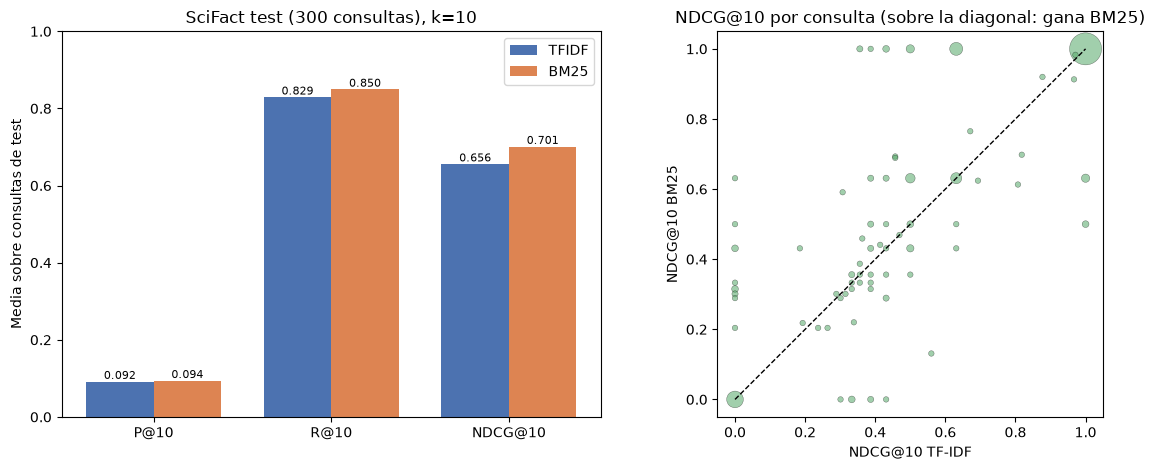

In [24]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))

# Barras de medias
x = np.arange(len(METRICAS))
for j, (m, color) in enumerate([("tfidf", "#4C72B0"), ("bm25", "#DD8452")]):
    vals = tabla.loc[m, METRICAS].to_numpy()
    barras = ax1.bar(x + (j - 0.5) * 0.38, vals, 0.38, label=m.upper(), color=color)
    ax1.bar_label(barras, fmt="%.3f", fontsize=8)
ax1.set_xticks(x, METRICAS)
ax1.set_ylim(0, 1)
ax1.set_ylabel("Media sobre consultas de test")
ax1.set_title(f"SciFact test ({len(eval_qids)} consultas), k=10")
ax1.legend()

# Dispersión NDCG@10 por consulta (tamaño = nº de consultas superpuestas)
pares = pd.DataFrame({"t": ancho[("NDCG@10", "tfidf")].round(3),
                      "b": ancho[("NDCG@10", "bm25")].round(3)})
cnt = pares.value_counts().reset_index(name="n")
ax2.scatter(cnt["t"], cnt["b"], s=12 + 4 * cnt["n"], alpha=0.55, color="#55A868", edgecolor="k", lw=0.3)
ax2.plot([0, 1], [0, 1], "k--", lw=1)
ax2.set_xlabel("NDCG@10 TF-IDF")
ax2.set_ylabel("NDCG@10 BM25")
ax2.set_title("NDCG@10 por consulta (sobre la diagonal: gana BM25)")
ax2.set_aspect("equal")
plt.tight_layout()
plt.show()

### 4.8. Consultas donde los modelos difieren más

Se eligen las 3 consultas con mayor $|\Delta\,NDCG@10|$, alternando el modelo ganador para ver casos en los dos sentidos. Para cada documento relevante se muestra la **posición** que ocupa en el ranking completo de cada modelo (no solo el top-10). "—" indica que no comparte ningún término con la consulta (score 0).

In [25]:
def posicion(engine, query, model, doc_id):
    """Posición (1-based) del documento en el ranking completo, o None si score = 0."""
    ids = [r["document_id"] for r in engine.search(query, model, index.N)]
    return ids.index(doc_id) + 1 if doc_id in ids else None

delta = (ancho[("NDCG@10", "bm25")] - ancho[("NDCG@10", "tfidf")]).sort_values()
# 2 donde más gana BM25 y 1 donde más gana TF-IDF
elegidas = list(delta.index[::-1][:2]) + [delta.index[0]]

for qid in elegidas:
    q = query_text[qid]
    print(f"Query {qid}  ΔNDCG@10 (BM25−TF-IDF) = {delta[qid]:+.3f}")
    print(f"  «{q}»")
    for did in qrels[qid]:
        pt, pb = posicion(engine, q, "tfidf", did), posicion(engine, q, "bm25", did)
        print(f"   relevante {did:>9}: TF-IDF pos {pt or '—':>4} | BM25 pos {pb or '—':>4} | "
              f"{index.titles[index.doc_ids.index(did)][:70]}")
    print(f"   top-3 TF-IDF: {runs['tfidf'][qid][:3]}   top-3 BM25: {runs['bm25'][qid][:3]}\n")

Query 72  ΔNDCG@10 (BM25−TF-IDF) = +0.644
  «Activator-inhibitor pairs are provided dorsally by Admpchordin.»
   relevante   6076903: TF-IDF pos    6 | BM25 pos    1 | Regulation of ADMP and BMP2/4/7 at Opposite Embryonic Poles Generates 
   top-3 TF-IDF: ['38380061', '2147704', '10937190']   top-3 BM25: ['6076903', '38380061', '1031534']

Query 569  ΔNDCG@10 (BM25−TF-IDF) = +0.644
  «In adult tissue, most T cells are memory T cells.»
   relevante  23460562: TF-IDF pos    6 | BM25 pos    1 | Early life compartmentalization of human T cell differentiation and re
   top-3 TF-IDF: ['3155731', '21320417', '37311371']   top-3 BM25: ['23460562', '3155731', '7492250']

Query 821  ΔNDCG@10 (BM25−TF-IDF) = -0.500
  «N-terminal cleavage reduces success identifying transcription start sites.»
   relevante   8646760: TF-IDF pos    1 | BM25 pos    3 | Identification and Functional Characterization of N-Terminally Acetyla
   top-3 TF-IDF: ['8646760', '35448676', '36540079']   top-3 BM25: ['36540079'

### 4.9. Ablación de BM25 (y TF-IDF): sin stemming y sin stopwords

Para medir el efecto de dos decisiones de preprocesamiento se reconstruye el índice con variantes de `preprocess`. Se sustituye temporalmente `app.preprocess`, que es la función que usan tanto `InvertedIndex.build` como `SearchEngine` para las consultas, y se restaura al terminar. `app.py` no se modifica.

In [26]:
original_preprocess = app.preprocess

def sin_stemming(text):
    return app.remove_stopwords(app.tokenize(app.normalize(text or "")))

def sin_stopwords(text):
    # se mantiene el filtro de longitud >= 2 para aislar solo el efecto de la lista de stopwords
    return [app.stem(t) for t in app.tokenize(app.normalize(text or "")) if len(t) >= app.MIN_LEN]

variantes = {"completo (actual)": original_preprocess,
             "sin stemming": sin_stemming,
             "sin stopwords": sin_stopwords}
filas = []
try:
    for nombre, fn in variantes.items():
        app.preprocess = fn
        idx_v = app.InvertedIndex().build(docs)
        eng_v = app.SearchEngine(idx_v)
        pq, _ = evaluar(eng_v, eval_qids)
        for m in MODELOS:
            fila = pq[pq.modelo == m][METRICAS].mean().round(4).to_dict()
            filas.append({"variante": nombre, "modelo": m, "vocabulario": len(idx_v.vocab),
                          "avgdl": round(idx_v.avgdl, 1), **fila})
finally:
    app.preprocess = original_preprocess          # restaurar siempre
assert app.preprocess("cells") == ["cell"]
ablacion = pd.DataFrame(filas).set_index(["modelo", "variante"]).sort_index(level=0, sort_remaining=False)
ablacion

vocabulario  avgdl    P@10    R@10  NDCG@10
modelo variante                                                      
bm25   completo (actual)        37974  151.7  0.0940  0.8495   0.7011
       sin stemming             47855  151.7  0.0887  0.7949   0.6729
       sin stopwords            38064  221.3  0.0923  0.8382   0.6937
tfidf  completo (actual)        37974  151.7  0.0917  0.8292   0.6557
       sin stemming             47855  151.7  0.0877  0.7892   0.6372
       sin stopwords            38064  221.3  0.0917  0.8292   0.6575

### Interpretación

*(Borrador basado en los resultados de las celdas anteriores; 300 consultas de test, k = 10.)*

**1. BM25 supera a TF-IDF en las tres métricas.**

| Métrica | TF-IDF | BM25 | Diferencia | Comparación por consulta | Wilcoxon |
|---|---|---|---|---|---|
| NDCG@10 | 0,656 | 0,701 | **+0,045** | gana BM25 en 76, TF-IDF en 41, empatan 183 | **significativa**, p ≈ 1,3·10⁻⁴ |
| Recall@10 | 0,829 | 0,850 | +0,020 | gana BM25 en 18, TF-IDF en 9 | no significativa, p ≈ 0,21 |
| Precision@10 | 0,092 | 0,094 | +0,002 | — | no significativa, p ≈ 0,16 |

En la mayoría de las consultas ambos modelos **encuentran** el mismo documento relevante dentro del top-10. La ventaja de BM25 está sobre todo en **colocarlo más arriba**: la consulta 72 y la 569 pasan de la posición 6 con TF-IDF a la 1 con BM25.

**2. Por qué BM25 ordena mejor.**
- **Saturación del tf ($k_1$):** el tf de BM25 crece hasta un límite, de modo que repetir un término muchas veces aporta cada vez menos. El $1+\ln tf$ de TF-IDF crece sin límite.
- **Normalización por longitud ($b$):** BM25 la hace respecto a `avgdl`. La normalización L2 del coseno puede favorecer documentos cortos o penalizar en exceso los largos.

BM25 no siempre gana. En la consulta 821 TF-IDF pone el relevante en la posición 1 y BM25 en la 3, y en 41 consultas TF-IDF obtiene mejor NDCG@10.

**3. Precision@10 no discrimina en este corpus.**
- El 92 % de las consultas tiene un solo documento relevante, así que el máximo alcanzable es 0,113.
- Los valores obtenidos (0,092 y 0,094) son ya el 81–83 % de ese techo.
- Por eso las métricas informativas son **Recall@10**, que indica si el relevante aparece en el top-10, y **NDCG@10**, que indica en qué posición aparece.

**4. Contexto y límites.**
- El NDCG@10 de BM25 (0,701) está algo por encima de la referencia de BEIR para SciFact (≈ 0,665, Elasticsearch con analizador estándar). Probablemente se debe al preprocesamiento: stemming Porter y expansión de los términos con guion.
- Con BM25 alrededor del 15 % de los relevantes no aparece en el top-10. Son en buena parte casos de **desajuste de vocabulario**: la afirmación y el resumen describen lo mismo con términos distintos. Es el límite propio de un modelo léxico.

**5. Ablación.**
- **Stemming:** es la decisión de preprocesamiento con más impacto. Sin él, BM25 baja de 0,701 a 0,673 en NDCG@10 y de 0,850 a 0,795 en Recall@10, y TF-IDF baja de 0,656 a 0,637.
- **Stopwords:** quitarlas apenas influye. BM25 mejora +0,007 con ellas, y TF-IDF queda prácticamente igual (0,656 con eliminación frente a 0,658 sin ella).
  - En TF-IDF el idf ya casi anula las palabras muy frecuentes.
  - En BM25 las stopwords alargan los documentos (`avgdl` pasa de 152 a 221 tokens) y alteran la normalización por longitud.
  - Su eliminación se justifica sobre todo por eficiencia: listas de postings más cortas y un índice más pequeño.

## 5. Servicio web

Se añade a `app.py` (con `%%writefile -a`) una API **FastAPI** que expone el motor de la sección 3. El servicio es solo JSON, sin frontend; por eso se desactivan `/docs` y `/redoc`, que son páginas HTML. Se arranca con `uvicorn app:app`.

### Diseño

- **Arranque (`lifespan`):** lee `corpus.jsonl`, situado junto a `app.py` (la ruta se puede cambiar con la variable de entorno `CORPUS_PATH`). Después construye `InvertedIndex` y `SearchEngine` **una sola vez**; cada petición solo consulta el índice en memoria.
- **`GET /health`** → `{"status": "ok", "documents": N, "models": ["bm25", "tfidf"]}`.
- **`POST /search`** con cuerpo `{"query": str, "model": "bm25"|"tfidf", "top_k": int}`, validado con Pydantic:
  - `query` es obligatoria, se le aplica `strip()`, no puede quedar vacía y admite como máximo 1000 caracteres;
  - `model` no distingue mayúsculas (`"BM25"` → `"bm25"`) y vale `"bm25"` por defecto;
  - `top_k` es un entero entre 1 y 100, con valor por defecto 10.
- **Errores de validación:** cualquier fallo (JSON mal formado, campos inválidos o ausentes) devuelve **422** con un JSON `{"detail": [...]}` que explica el problema.
- **Respuesta:** exactamente `{"model": ..., "results": [{rank, document_id, score, title, snippet}]}`, garantizado por `response_model`. El orden, la ausencia de duplicados y el máximo de `top_k` vienen de `SearchEngine.search`.
- **Consulta sin términos útiles:** una consulta válida pero sin términos indexables (por ejemplo, solo stopwords) **no es un error**: devuelve 200 con `"results": []`.

In [27]:
%%writefile -a app.py


# -----------------------------------------------------------------------------
# 4) Servicio web (FastAPI, solo JSON)
#    Arranque:  uvicorn app:app --host 0.0.0.0 --port 8000
# -----------------------------------------------------------------------------
import os
import time
from contextlib import asynccontextmanager
from typing import List, Literal

from fastapi import FastAPI
from pydantic import BaseModel, Field, field_validator

CORPUS_PATH = os.environ.get(
    "CORPUS_PATH", os.path.join(os.path.dirname(os.path.abspath(__file__)), "corpus.jsonl"))
MAX_QUERY_CHARS = 1000
MAX_TOP_K = 100

STATE = {}     # se rellena en el arranque: index, engine, tiempo de carga


@asynccontextmanager
async def lifespan(_app):
    """Al arrancar: lee corpus.jsonl y construye índice + motor (una sola vez)."""
    t0 = time.perf_counter()
    index = InvertedIndex().build(load_corpus(CORPUS_PATH))
    STATE["index"] = index
    STATE["engine"] = SearchEngine(index)
    STATE["startup_seconds"] = round(time.perf_counter() - t0, 2)
    print(f"[app] Índice listo: {index.N} documentos, {len(index.vocab)} términos "
          f"en {STATE['startup_seconds']} s", flush=True)
    yield
    STATE.clear()


class SearchRequest(BaseModel):
    """Cuerpo de POST /search."""
    query: str = Field(..., description="Texto libre de la consulta (no vacío, máx. 1000 caracteres)")
    model: str = Field("bm25", description="'bm25' o 'tfidf' (sin distinguir mayúsculas)")
    top_k: int = Field(10, ge=1, le=MAX_TOP_K, description="Número de resultados, 1..100")

    @field_validator("query")
    @classmethod
    def _query_ok(cls, v):
        v = v.strip()
        if not v:
            raise ValueError("query no puede estar vacía")
        if len(v) > MAX_QUERY_CHARS:
            raise ValueError(f"query no puede superar {MAX_QUERY_CHARS} caracteres")
        return v

    @field_validator("model", mode="before")
    @classmethod
    def _model_ok(cls, v):
        if not isinstance(v, str):
            raise ValueError("model debe ser una cadena: 'bm25' o 'tfidf'")
        v = v.strip().lower()
        if v not in SearchEngine.MODELS:
            raise ValueError("model debe ser 'bm25' o 'tfidf'")
        return v


class SearchResult(BaseModel):
    rank: int
    document_id: str
    score: float
    title: str
    snippet: str


class SearchResponse(BaseModel):
    model: Literal["bm25", "tfidf"]
    results: List[SearchResult]


# Sin /docs ni /redoc (páginas HTML): el servicio es solo JSON.
app = FastAPI(
    title="SciFact IR - TF-IDF y BM25",
    description="Recuperación léxica sobre BeIR/scifact. Solo JSON.",
    version="1.0.0",
    lifespan=lifespan,
    docs_url=None,
    redoc_url=None,
)


@app.get("/")
def root():
    """Descripción mínima del servicio (JSON)."""
    return {"service": "SciFact IR (TF-IDF coseno y BM25)",
            "endpoints": {"GET /health": "disponibilidad",
                          "POST /search": {"query": "str", "model": "bm25 | tfidf",
                                           "top_k": "int 1..100"}}}


@app.get("/health")
def health():
    return {"status": "ok", "documents": STATE["index"].N, "models": ["bm25", "tfidf"]}


@app.post("/search", response_model=SearchResponse)
def search(req: SearchRequest):
    # Consulta sin términos útiles (p. ej. solo stopwords) -> 200 con results []
    results = STATE["engine"].search(req.query, req.model, req.top_k)
    return {"model": req.model, "results": results}


Appending to app.py


### 5.1. Recargar `app` y reconstruir el índice

Se recarga el módulo con la API ya añadida y se reconstruyen el índice y el motor del notebook. Así las comparaciones de abajo se hacen con exactamente el mismo código que sirve la API.

In [28]:
importlib.reload(app)
docs = app.load_corpus("corpus.jsonl")
index = app.InvertedIndex().build(docs)
engine = app.SearchEngine(index)
print("Rutas de la API:", [(sorted(r.methods), r.path) for r in app.app.routes if hasattr(r, "methods")])

Rutas de la API: [(['GET', 'HEAD'], '/openapi.json'), (['GET'], '/'), (['GET'], '/health'), (['POST'], '/search')]


### 5.2. Prueba (a): `fastapi.testclient`

`TestClient` ejecuta la aplicación en el mismo proceso, incluido el `lifespan`, sin abrir puertos. Se comprueban:
- el formato exacto de las respuestas;
- el orden descendente, la ausencia de duplicados y que no se supere `top_k`, con ambos modelos;
- que los resultados sean idénticos a llamar al motor directamente;
- el rechazo de entradas inválidas;
- 5 consultas nuevas que no pertenecen al conjunto de test.

In [29]:
from fastapi.testclient import TestClient

CLAVES_RESULTADO = {"rank", "document_id", "score", "title", "snippet"}
ids_corpus = set(index.doc_ids)

def validar_respuesta(body, model, top_k):
    """Comprueba formato exacto, orden, duplicados y top_k de una respuesta /search."""
    assert set(body) == {"model", "results"}, body.keys()
    assert body["model"] == model
    res = body["results"]
    assert len(res) <= top_k
    assert all(set(r) == CLAVES_RESULTADO for r in res)
    assert all(isinstance(r["document_id"], str) and r["document_id"] in ids_corpus for r in res)
    sc = [r["score"] for r in res]
    assert all(a >= b for a, b in zip(sc, sc[1:])), "orden"
    assert len({r["document_id"] for r in res}) == len(res), "duplicados"
    assert [r["rank"] for r in res] == list(range(1, len(res) + 1))

with TestClient(app.app) as client:
    # --- health ---
    h = client.get("/health")
    assert h.status_code == 200 and h.json() == {"status": "ok", "documents": 5183, "models": ["bm25", "tfidf"]}
    print("GET /health ->", h.json())

    # --- formato / orden / duplicados / top_k con queries de test, ambos modelos ---
    n = 0
    for qid in eval_qids[:50]:
        for model in ("bm25", "tfidf"):
            for k in (1, 10, 100):
                r = client.post("/search", json={"query": query_text[qid], "model": model, "top_k": k})
                assert r.status_code == 200
                validar_respuesta(r.json(), model, k)
                # mismos resultados que el motor llamado directamente
                assert r.json()["results"] == engine.search(query_text[qid], model, k)
                n += 1
    print(f"{n} peticiones /search válidas: formato, orden, sin duplicados, top_k e igualdad con el motor OK")

    # --- valores por defecto y model sin distinguir mayúsculas ---
    r = client.post("/search", json={"query": "stem cells"}).json()
    assert r["model"] == "bm25" and len(r["results"]) == 10
    r = client.post("/search", json={"query": "stem cells", "model": " TFIDF ", "top_k": 3}).json()
    assert r["model"] == "tfidf" and len(r["results"]) == 3
    print("Defaults (bm25, top_k=10) y model case-insensitive OK")

    # --- solo stopwords / términos desconocidos -> 200 con lista vacía ---
    for q in ["the of and is", "zzqxjw blorptastic"]:
        r = client.post("/search", json={"query": q, "model": "tfidf"})
        assert r.status_code == 200 and r.json() == {"model": "tfidf", "results": []}
    print("Solo stopwords / desconocidos -> 200, results [] OK")

    # --- entradas inválidas -> 422 con JSON ---
    invalidos = {
        "query vacía": {"query": ""},
        "query solo espacios": {"query": "   "},
        "sin query": {"model": "bm25"},
        "query > 1000 caracteres": {"query": "a" * 1001},
        "query no string": {"query": 123},
        "model desconocido": {"query": "cancer", "model": "lsi"},
        "model no string": {"query": "cancer", "model": 1},
        "top_k = 0": {"query": "cancer", "top_k": 0},
        "top_k = 101": {"query": "cancer", "top_k": 101},
        "top_k no entero": {"query": "cancer", "top_k": "diez"},
    }
    for nombre, body in invalidos.items():
        r = client.post("/search", json=body)
        assert r.status_code == 422 and "detail" in r.json(), (nombre, r.status_code)
        print(f"  422 {nombre:24s} -> {r.json()['detail'][0]['msg']}")
    r = client.post("/search", content="{no es json", headers={"Content-Type": "application/json"})
    assert r.status_code == 422
    print(f"  422 {'JSON mal formado':24s} -> {r.json()['detail'][0]['msg']}")
    assert client.get("/search").status_code == 405
    assert client.get("/docs").status_code == 404              # sin frontend

    # --- 5 consultas nuevas (no están en test) ---
    textos_test = {query_text[q].lower() for q in eval_qids}
    nuevas = ["Vitamin D supplementation reduces the risk of bone fractures in elderly people",
              "gut microbiota composition is associated with obesity",
              "aspirin lowers colorectal cancer incidence",
              "CRISPR-Cas9 off-target mutations",
              "Does smoking during pregnancy affect birth weight?"]
    for q in nuevas:
        assert q.lower() not in textos_test
        print(f"\nNueva consulta: «{q}»")
        for model in ("bm25", "tfidf"):
            r = client.post("/search", json={"query": q, "model": model, "top_k": 3})
            assert r.status_code == 200
            validar_respuesta(r.json(), model, 3)
            for x in r.json()["results"]:
                print(f"   {model:5s} {x['rank']}. [{x['document_id']:>9}] {x['score']:7.4f}  {x['title'][:70]}")
print("\nOK: todas las pruebas con TestClient superadas.")

[app] Índice listo: 5183 documentos, 37974 términos en 1.93 s


GET /health -> {'status': 'ok', 'documents': 5183, 'models': ['bm25', 'tfidf']}


300 peticiones /search válidas: formato, orden, sin duplicados, top_k e igualdad con el motor OK
Defaults (bm25, top_k=10) y model case-insensitive OK
Solo stopwords / desconocidos -> 200, results [] OK
  422 query vacía              -> Value error, query no puede estar vacía
  422 query solo espacios      -> Value error, query no puede estar vacía
  422 sin query                -> Field required
  422 query > 1000 caracteres  -> Value error, query no puede superar 1000 caracteres
  422 query no string          -> Input should be a valid string
  422 model desconocido        -> Value error, model debe ser 'bm25' o 'tfidf'
  422 model no string          -> Value error, model debe ser una cadena: 'bm25' o 'tfidf'
  422 top_k = 0                -> Input should be greater than or equal to 1
  422 top_k = 101              -> Input should be less than or equal to 100
  422 top_k no entero          -> Input should be a valid integer, unable to parse string as an integer
  422 JSON mal formado

### 5.3. Prueba (b): servidor real con `uvicorn` y cliente `httpx`

Se lanza `uvicorn app:app` como **subproceso** con el Python del `.venv` (`sys.executable`, que es el del kernel) en un puerto libre de `127.0.0.1`. Se espera a que `/health` responda y se hacen peticiones HTTP reales con `httpx`, igual que hará un cliente como Postman. Se mide la latencia de extremo a extremo y al final el servidor se detiene.

In [30]:
import os, socket, subprocess, sys, json as _json
import httpx

with socket.socket() as s:                       # puerto libre
    s.bind(("127.0.0.1", 0))
    PORT = s.getsockname()[1]
BASE = f"http://127.0.0.1:{PORT}"

proc = subprocess.Popen(
    [sys.executable, "-m", "uvicorn", "app:app", "--host", "127.0.0.1", "--port", str(PORT),
     "--log-level", "warning"],
    stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, encoding="utf-8",
    env={**os.environ, "PYTHONIOENCODING": "utf-8"})
print("Python del servidor (relativo al proyecto):", os.path.relpath(sys.executable))
try:
    # Esperar a que el servidor esté listo (construye el índice al arrancar)
    t0 = time.perf_counter()
    while True:
        try:
            if httpx.get(f"{BASE}/health", timeout=1).status_code == 200:
                break
        except httpx.TransportError:
            pass
        if proc.poll() is not None or time.perf_counter() - t0 > 90:
            raise RuntimeError("uvicorn no arrancó:\n" + (proc.stdout.read() if proc.poll() is not None else ""))
        time.sleep(0.3)
    print(f"Servidor listo en {BASE} tras {time.perf_counter() - t0:.1f} s\n")

    with httpx.Client(base_url=BASE, timeout=10) as cli:
        r = cli.get("/health")
        print("GET /health", r.status_code, r.json())

        body = {"query": "Vitamin D deficiency is linked to multiple sclerosis", "model": "bm25", "top_k": 3}
        r = cli.post("/search", json=body)
        print("\nPOST /search", body, "->", r.status_code)
        print(_json.dumps(r.json(), indent=2, ensure_ascii=False)[:1500])

        r = cli.post("/search", json={"query": "  ", "model": "bm25"})
        print("\nPOST /search query vacía ->", r.status_code, r.json()["detail"][0]["msg"])

        # Latencia: todas las queries de test, ambos modelos, top_k=10
        lat = {m: [] for m in ("bm25", "tfidf")}
        for qid in eval_qids:
            for m in lat:
                t = time.perf_counter()
                rr = cli.post("/search", json={"query": query_text[qid], "model": m, "top_k": 10})
                lat[m].append(1000 * (time.perf_counter() - t))
                assert rr.status_code == 200 and len(rr.json()["results"]) <= 10
        print("\nLatencia HTTP extremo a extremo (ms) en", len(eval_qids), "consultas de test:")
        print(pd.DataFrame({m: pd.Series(v).describe(percentiles=[.5, .95])[["mean", "50%", "95%", "max"]]
                            for m, v in lat.items()}).round(2).T)
finally:
    proc.terminate()
    proc.wait(timeout=10)
    print("\nServidor detenido. Log de uvicorn:\n" + (proc.stdout.read().strip() or "(vacío)"))

Python del servidor (relativo al proyecto): .venv\Scripts\python.exe


Servidor listo en http://127.0.0.1:52922 tras 5.0 s



GET /health 200 {'status': 'ok', 'documents': 5183, 'models': ['bm25', 'tfidf']}

POST /search {'query': 'Vitamin D deficiency is linked to multiple sclerosis', 'model': 'bm25', 'top_k': 3} -> 200
{
  "model": "bm25",
  "results": [
    {
      "rank": 1,
      "document_id": "22843838",
      "score": 22.198783271213053,
      "title": "[Vitamin D and latitude as environmental factors in multiple sclerosis].",
      "snippet": "Multiple sclerosis (MS) shows a multifold increase in prevalence with an increase in latitudes, both north and south of the equator. One of the potential factors related to the difference of the prevalence is vitamin D, because the strength of ambient ultraviolet light, which is essential for..."
    },
    {
      "rank": 2,
      "document_id": "21553394",
      "score": 16.31067203389564,
      "title": "Vitamin D and obesity: current perspectives and future directions.",
      "snippet": "In recent years, new functional roles of vitamin D beyond its traditi


Latencia HTTP extremo a extremo (ms) en 300 consultas de test:
       mean   50%   95%   max
bm25   1.76  1.68  2.31  3.57
tfidf  1.77  1.70  2.40  2.87

Servidor detenido. Log de uvicorn:
[app] Índice listo: 5183 documentos, 37974 términos en 2.77 s


## Conclusiones

*(Borrador basado en los resultados de las secciones 2–5.)*

1. **Sistema completo y verificado.**
   - El índice invertido contiene los 5183 documentos con sus `_id` originales y un vocabulario de 37 974 términos.
   - Las dos implementaciones term-at-a-time coinciden con una versión densa ingenua: `np.allclose`, diferencia máxima ≈ 10⁻¹⁵.
   - Las métricas propias coinciden exactamente con `pytrec_eval`.
2. **BM25 es el mejor modelo en SciFact.**
   - NDCG@10: 0,701 frente a 0,656 de TF-IDF, diferencia significativa según Wilcoxon (p ≈ 1,3·10⁻⁴).
   - Recall@10: 0,850 frente a 0,829.
   - La mejora está sobre todo en *dónde* coloca el documento relevante dentro del top-10, gracias a la saturación del tf y a la normalización por longitud.
3. **La métrica adecuada importa.** Con ≈ 1,13 relevantes por consulta, P@10 tiene un techo de 0,113 y apenas distingue los modelos. Recall@10 y NDCG@10 son las métricas informativas.
4. **El preprocesamiento cuenta.**
   - El stemming Porter aporta ≈ +0,03 de NDCG@10 y +0,055 de Recall@10 a BM25.
   - Eliminar stopwords apenas cambia la calidad, aunque reduce el índice.
   - El tratamiento de guiones, números y letras griegas se diseñó para la nomenclatura biomédica (`IL-6`, `p53`, `TNF-α`).
5. **Servicio.** La API valida las entradas (422 con JSON ante errores) y devuelve el formato exigido. Responde en ≈ 2 ms en local, porque el índice se construye una vez al arrancar.
6. **Limitaciones.**
   - Al ser un modelo léxico, falla cuando la afirmación y el resumen usan vocabulario distinto: ≈ 15 % de los relevantes queda fuera del top-10 con BM25.
   - Mejoras posibles dentro del enfoque léxico: ajustar $k_1$ y $b$ con las consultas de *train*, o expandir la consulta con *pseudo-relevance feedback* (RM3).